# Prediksi Harga Mobil Bekas

Tugas Pengenalan Pola - Machine Learning (regresi)

**Tujuan:** memprediksi `price_usd` (harga mobil bekas) dari data mobil seperti tahun, mesin, merek, dll.

**Metrik:** MAE, RMSE, dan R2. Model harus lebih bagus dari baseline (prediksi rata-rata harga).

**Alur:**
1. Baca data dan cek data
2. Cleaning (missing value, duplikat, outlier)
3. EDA
4. Feature engineering
5. Split train dan test
6. Preprocessing (encoding dan scaling)
7. Bandingkan model pakai cross validation
8. Tuning
9. Evaluasi di data test
10. Simpan model dan deploy

## 1. Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

**Penjelasan Kode:**
Mengimpor pustaka pengolahan data (`pandas`, `numpy`), grafik (`matplotlib`, `seaborn`), penyimpanan model (`joblib`, `json`), serta perangkat *workflow* Scikit-Learn: `ColumnTransformer` & `Pipeline` untuk mencegah kebocoran data, `DummyRegressor` untuk patokan dasar (*baseline*), `cross_validate` & `GridSearchCV` untuk validasi silang dan *tuning*, serta `permutation_importance` untuk mengukur pengaruh tiap fitur.

## 2. Baca data dan cek data

In [2]:
df = pd.read_csv('used_car_prediction.csv')

In [3]:
df.head()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
0,2001,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,NaN,0,No
1,2014,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,NaN,0,Yes
2,2023,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes
3,2009,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes
4,2005,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes


In [4]:
df.shape

(10000, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           10000 non-null  int64  
 1   mileage_kmpl        10000 non-null  float64
 2   engine_cc           10000 non-null  int64  
 3   fuel_type           10000 non-null  str    
 4   owner_count         10000 non-null  int64  
 5   price_usd           10000 non-null  float64
 6   brand               10000 non-null  str    
 7   transmission        10000 non-null  str    
 8   color               10000 non-null  str    
 9   service_history     7962 non-null   str    
 10  accidents_reported  10000 non-null  int64  
 11  insurance_valid     10000 non-null  str    
dtypes: float64(2), int64(4), str(6)
memory usage: 1.2 MB


**Penjelasan Output `df.info()`:**
Data terdiri dari **10.000 baris** dan **12 kolom** (6 angka, 6 teks). Terlihat hanya kolom `service_history` yang jumlahnya belum genap 10.000 (7.962 *non-null*), artinya terdapat **2.038 baris kosong** yang akan dibersihkan pada tahap berikutnya.

In [6]:
df.describe()

,make_year,mileage_kmpl,engine_cc,owner_count,price_usd,accidents_reported
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2009.206900,17.960753,2287.130000,3.003500,7179.754532,0.492200
std,8.373858,5.025486,1291.276927,1.418904,2795.270940,0.694109
min,1995.000000,5.000000,800.000000,1.000000,1000.000000,0.000000
25%,2002.000000,14.540000,1200.000000,2.000000,5176.547500,0.000000
50%,2009.000000,17.970000,1800.000000,3.000000,6961.260000,0.000000
75%,2016.000000,21.352500,3000.000000,4.000000,8993.732500,1.000000
max,2023.000000,35.000000,5000.000000,5.000000,17647.630000,5.000000


**Penjelasan Tabel `df.describe()`:**
Ringkasan statistik ini menunjukkan tahun mobil berkisar antara **1995–2023**, harga (`price_usd`) antara **$1.000–$17.647** (rata-rata **$7.180**), dan jumlah pemilik 1–5 orang. Catatan penting: `mileage_kmpl` di sini adalah **efisiensi bahan bakar (km per liter)**, bukan jarak tempuh odometer.

## 3. Cleaning

In [7]:
# cek missing value
df.isnull().sum()

make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64

In [8]:
# cek duplikat
df.duplicated().sum()

np.int64(0)

Missing value cuma ada di `service_history`. Barisnya tidak dihapus karena jumlahnya cukup banyak, jadi diisi `Unknown` (artinya tidak ada catatan servis). Mengisi dengan nilai tetap seperti ini tidak bikin data leakage, jadi aman dilakukan sebelum split.

In [9]:
df['service_history'] = df['service_history'].fillna('Unknown')
df.isnull().sum().sum()

np.int64(0)

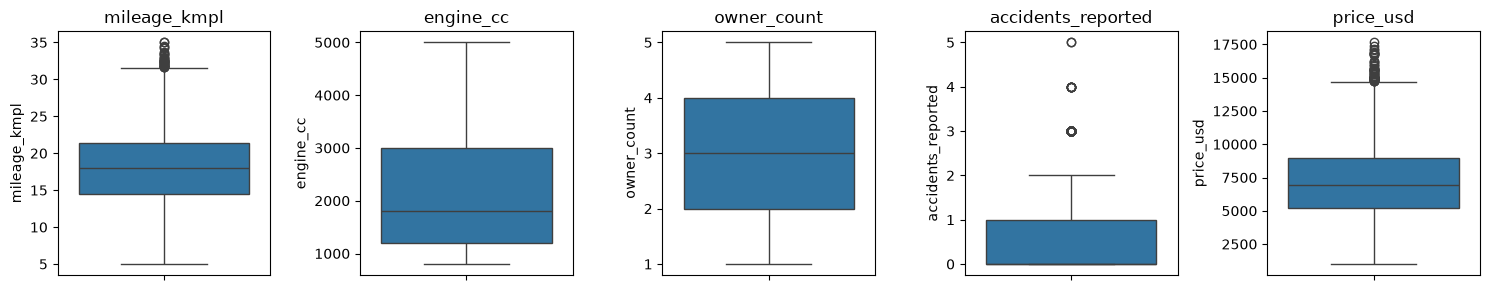

In [10]:
# cek outlier pakai boxplot
kolom_num = ['mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'price_usd']

plt.figure(figsize=(15, 3))
for i, col in enumerate(kolom_num):
    plt.subplot(1, 5, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

**Penjelasan Grafik (Boxplot Outlier):**
Kotak menunjukkan rentang 50% data tengah, garis di dalam kotak adalah *median*, dan titik-titik bulat di luar garis batas atas/bawah (*whisker*) adalah kandidat *outlier*. Titik ekstrem terlihat di bagian atas `mileage_kmpl`, `accidents_reported`, dan `price_usd`, tetapi nilainya masih masuk akal untuk mobil sungguhan (misal keiritan 35 km/l atau harga mobil ~$17.600), sehingga tidak perlu dibuang.

In [11]:
# cek nilai yang tidak masuk akal
print('harga <= 0         :', (df['price_usd'] <= 0).sum())
print('tahun > 2026       :', (df['make_year'] > 2026).sum())
print('owner_count < 1    :', (df['owner_count'] < 1).sum())
print('accidents < 0      :', (df['accidents_reported'] < 0).sum())

harga <= 0         : 0
tahun > 2026       : 0
owner_count < 1    : 0
accidents < 0      : 0


In [12]:
# cek fuel_type vs engine_cc (mobil listrik harusnya tidak punya cc)
df.groupby('fuel_type')[['engine_cc', 'mileage_kmpl']].describe().T

fuel_type                Diesel     Electric       Petrol
engine_cc    count  4058.000000   974.000000  4968.000000
             mean   2305.446033  2261.704312  2277.153784
             std    1301.226137  1268.400669  1287.621836
             min     800.000000   800.000000   800.000000
             25%    1200.000000  1200.000000  1200.000000
             50%    2000.000000  1800.000000  1800.000000
             75%    3000.000000  3000.000000  3000.000000
             max    5000.000000  5000.000000  5000.000000
mileage_kmpl count  4058.000000   974.000000  4968.000000
             mean     17.974256    18.053583    17.931524
             std       4.945536     5.024415     5.090799
             min       5.000000     5.000000     5.000000
             25%      14.460000    14.855000    14.550000
             50%      17.970000    18.135000    17.940000
             75%      21.397500    21.327500    21.342500
             max      34.990000    33.440000    35.000000

**Penjelasan Kode & Kesimpulan Cleaning:**
- Kode `groupby('fuel_type')...describe().T` mengecek statistik kapasitas mesin dan keiritan BBM untuk tiap jenis bahan bakar (`.T` memutar tampilan tabel agar mudah dibaca).
- **Hasil:** Tidak ada harga negatif atau tahun di luar batas wajar, sehingga *outlier* tidak dihapus. Namun, terlihat mobil `Electric` di tabel terakhir tetap memiliki `engine_cc` (800–5.000 cc). Ini menandakan dataset bersifat sintetis/simulasi—datanya tetap dipakai agar kategori mobil listrik tidak hilang, tetapi dicatat sebagai keterbatasan dataset.

## 4. EDA

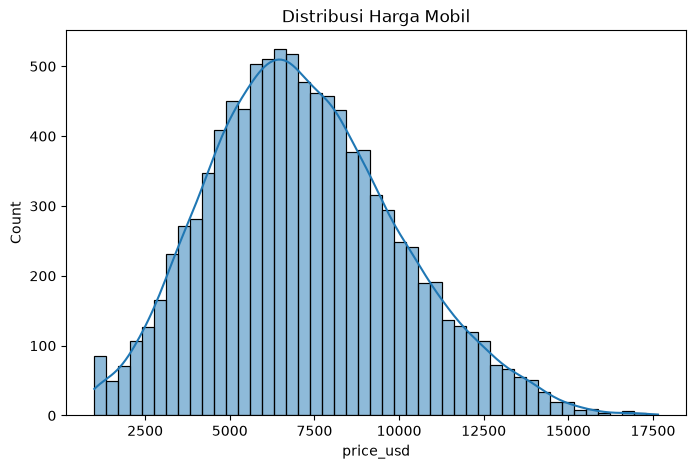

skewness harga: 0.35590379484454754


In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='price_usd', kde=True)
plt.title('Distribusi Harga Mobil')
plt.show()

print('skewness harga:', df['price_usd'].skew())

**Penjelasan Grafik (Distribusi Harga Mobil):**
Sebagian besar harga mobil bekas berkumpul di rentang **$5.000 hingga $9.000** dengan batas bawah tepat di **$1.000**. Nilai *skewness* sekitar **0,36** (hanya miring tipis ke kanan karena sedikit mobil di atas $14.000), sehingga distribusinya cukup mendekati normal dan tidak memerlukan transformasi logaritma pada target harga.

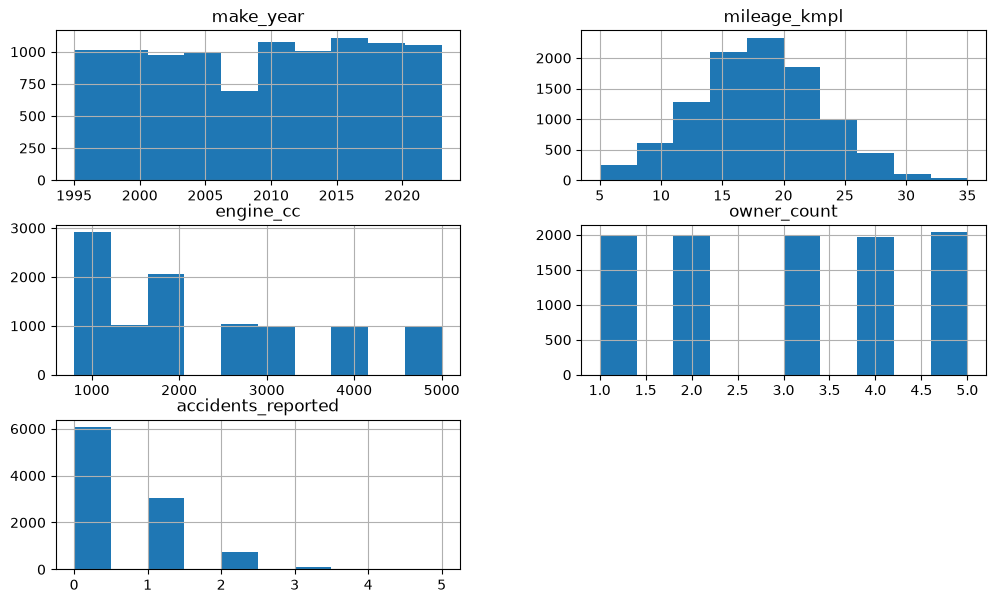

In [14]:
df[['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported']].hist(figsize=(12, 7))
plt.show()

**Penjelasan Grafik (Distribusi Fitur Numerik):**
- **`make_year` & `owner_count`:** Tersebar cukup merata dari tahun 1995–2023 dan 1–5 pemilik.
- **`mileage_kmpl`:** Berbentuk lonceng simetris (distribusi normal) di sekitar 18 km/liter.
- **`engine_cc`:** Berupa kelompok angka diskrit sesuai ukuran mesin standar pabrik (1.000 cc, 1.500 cc, dst. hingga 5.000 cc).
- **`accidents_reported`:** Mayoritas menumpuk di angka 0 dan 1 kali kecelakaan.

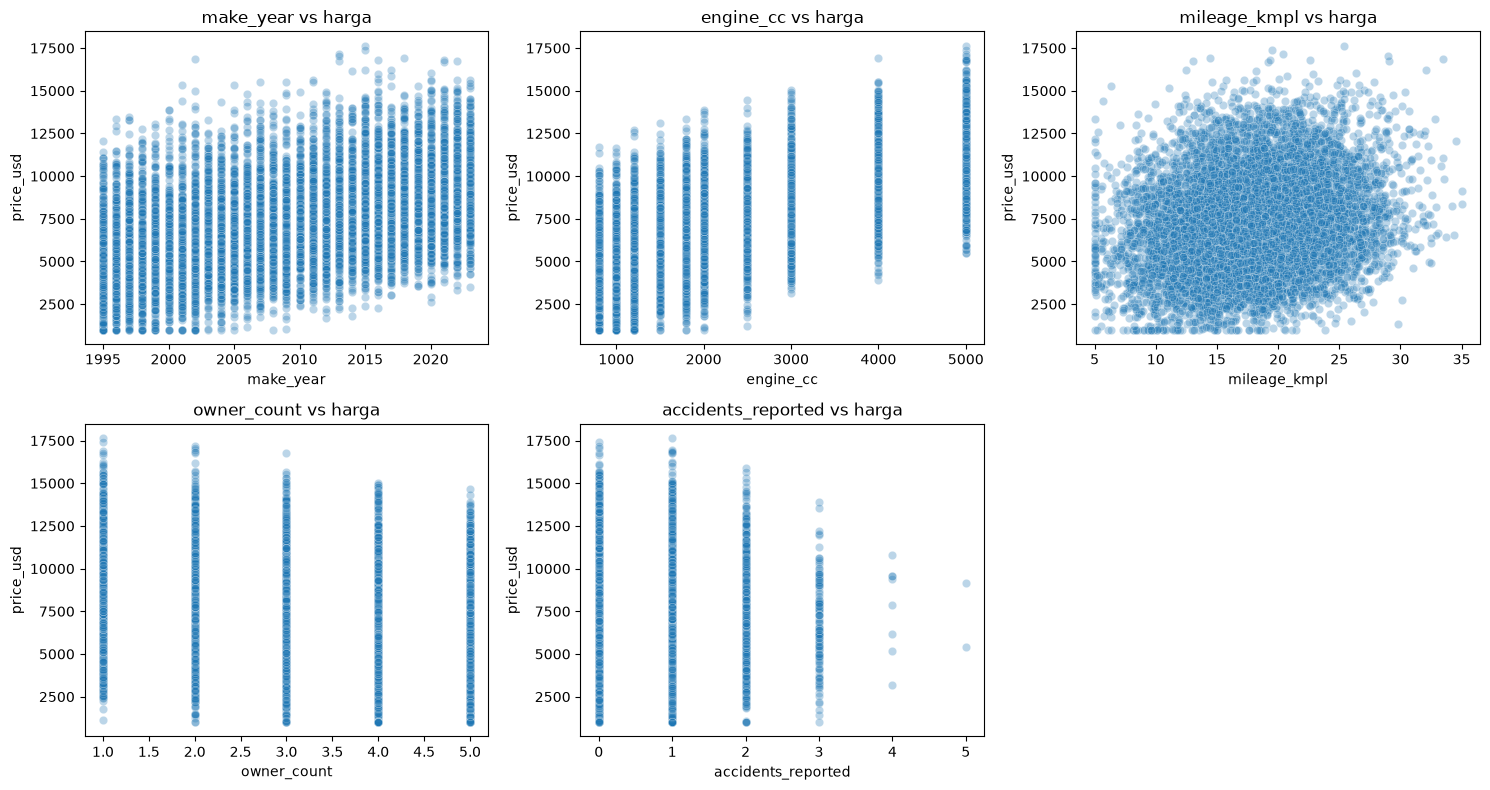

In [15]:
# fitur numerik vs harga
plt.figure(figsize=(15, 8))
for i, col in enumerate(['make_year', 'engine_cc', 'mileage_kmpl', 'owner_count', 'accidents_reported']):
    plt.subplot(2, 3, i + 1)
    sns.scatterplot(data=df, x=col, y='price_usd', alpha=0.3)
    plt.title(col + ' vs harga')
plt.tight_layout()
plt.show()

**Penjelasan Grafik (Scatterplot Fitur Numerik vs Harga):**
- **`make_year` & `engine_cc` vs harga:** Memperlihatkan tren naik paling kuat—mobil yang lebih muda tahunnya dan lebih besar CC mesinnya cenderung makin mahal.
- **`mileage_kmpl` vs harga:** Tren naik tipis (mobil irit sedikit lebih tinggi harganya).
- **`owner_count` vs harga:** Tren turun tipis (makin banyak mantan pemilik, harga jual makin turun).
- **`accidents_reported` vs harga:** Sebaran titik tampak datar di semua angka kecelakaan, menandakan pengaruhnya sangat lemah di data ini.

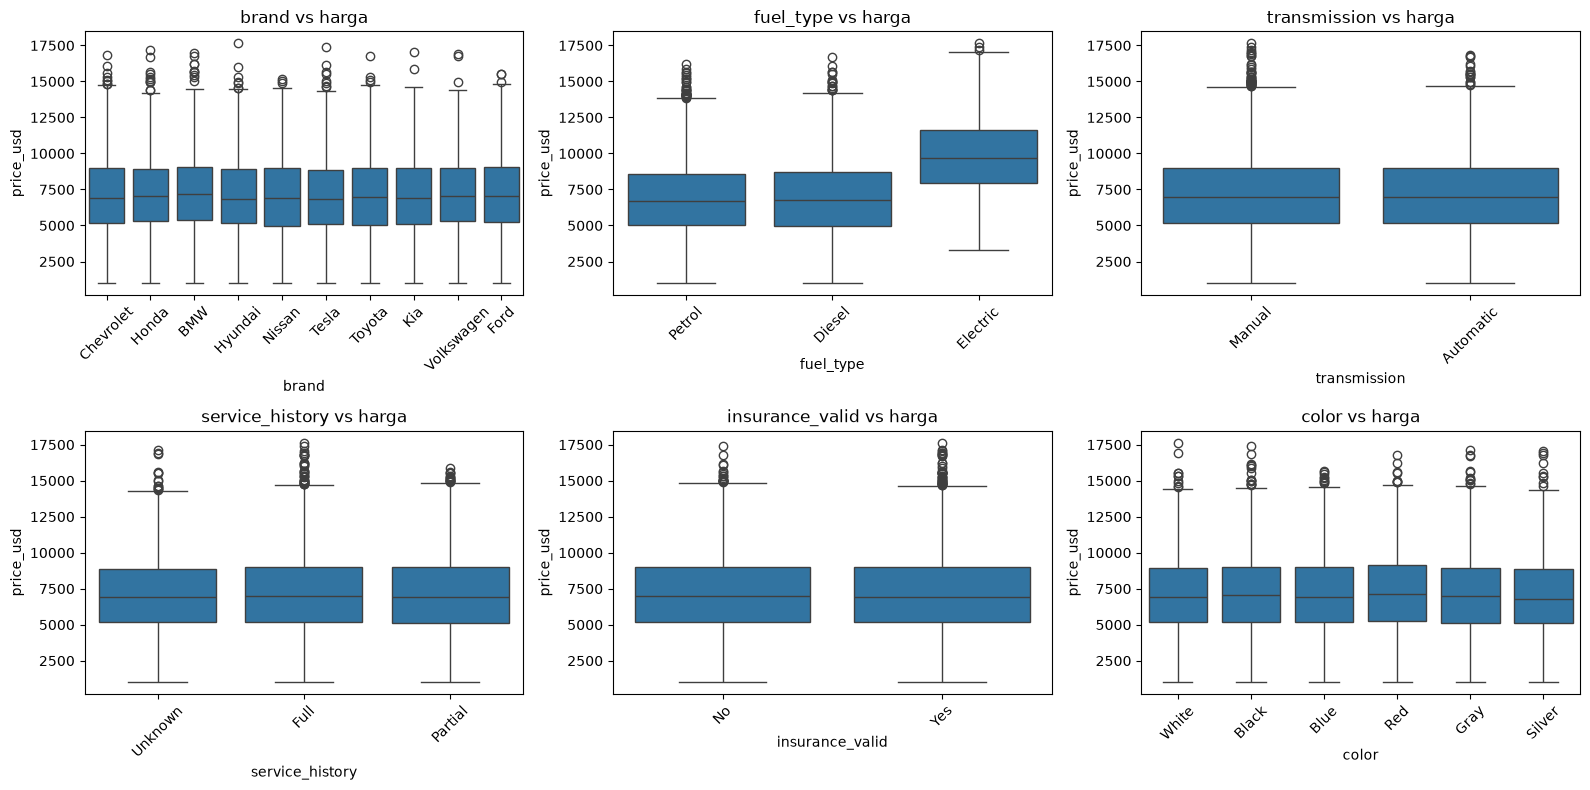

In [16]:
# fitur kategorikal vs harga
kolom_kat = ['brand', 'fuel_type', 'transmission', 'service_history', 'insurance_valid', 'color']

plt.figure(figsize=(16, 8))
for i, col in enumerate(kolom_kat):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(data=df, x=col, y='price_usd')
    plt.xticks(rotation=45)
    plt.title(col + ' vs harga')
plt.tight_layout()
plt.show()

**Penjelasan Grafik (Boxplot Fitur Kategorikal vs Harga):**
Garis tengah pada tiap kotak menandakan nilai *median* harga per kategori.
- Perbedaan mencolok hanya tampak pada **`fuel_type`**, di mana mobil **`Electric`** jauh lebih mahal (median ~$9.685) dibanding `Diesel` dan `Petrol` (~$6.700).
- Untuk **`brand`, `transmission`, `service_history`, `insurance_valid`, dan `color`**, tinggi dan posisi kotak antar kategori tampak hampir sejajar (~$6.800–$7.150), menandakan kategori tersebut tidak banyak membedakan harga secara terpisah.

In [17]:
df.groupby('color')['price_usd'].agg(['count', 'mean', 'median']).sort_values('median', ascending=False)

,count,mean,median
color,,,
Red,1678,7287.139678,7133.540
Black,1702,7216.539318,7027.635
Gray,1705,7190.391296,6971.680
White,1651,7147.743137,6915.310
Blue,1634,7197.815367,6898.645
Silver,1630,7033.989957,6803.635


**Penjelasan Kode:**
Mengelompokkan mobil berdasarkan warna (`color`) untuk melihat jumlah sampel, rata-rata, dan median harganya. Selisih median warna tertinggi (`Red`) dan terendah (`Silver`) hanya sekitar $330 dari harga rata-rata $7.000-an.

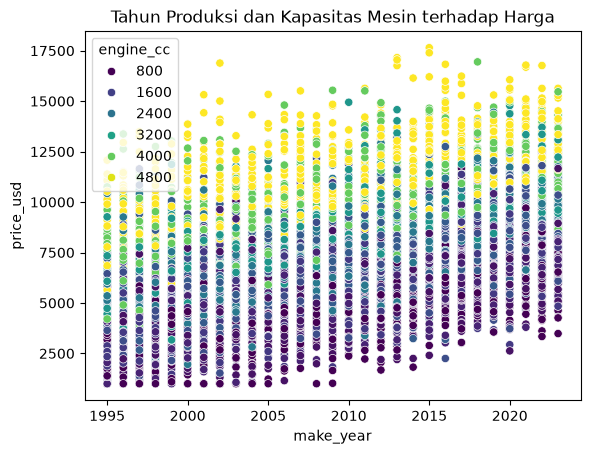

In [18]:
# apakah mobil baru dan mesin besar lebih mahal?
sns.scatterplot(data=df, x='make_year', y='price_usd', hue='engine_cc', palette='viridis')
plt.title('Tahun Produksi dan Kapasitas Mesin terhadap Harga')
plt.show()

**Penjelasan Grafik (Tahun Produksi & Kapasitas Mesin terhadap Harga):**
Grafik ini memadukan 3 informasi sekaligus: **Tahun Produksi** (sumbu X), **Harga** (sumbu Y), dan **Kapasitas Mesin** (gradasi warna titik). Titik berwarna kuning/hijau terang (mesin besar 4.000–5.000 cc) selalu berada di lapisan paling atas dan kian menanjak di tahun yang lebih baru—menunjukkan bahwa kombinasi mobil muda + mesin besar menghasilkan harga tertinggi.

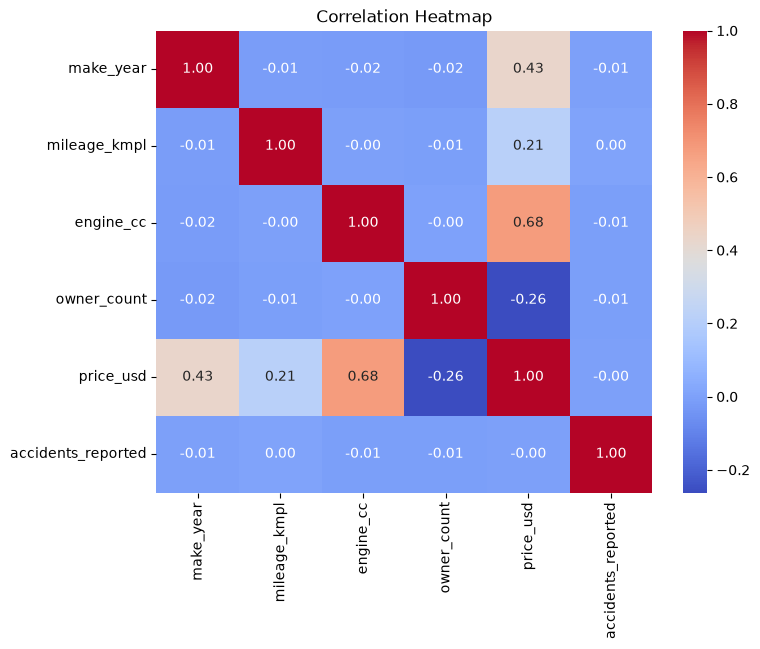

In [19]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

**Penjelasan Grafik (Correlation Heatmap) & Catatan EDA:**
- **Cara baca Heatmap:** Angka mendekati **+1** berarti hubungan searah yang kuat, mendekati **-1** berlawanan arah, dan **0** berarti tidak ada hubungan lurus (*linear*). Korelasi hanya menghitung kolom bertipe angka.
- Terhadap `price_usd`, hubungan positif terkuat ada pada **`engine_cc` (0.68)** dan **`make_year` (0.43)**, disusul **`mileage_kmpl` (0.21)**. Kolom **`owner_count` (-0.26)** bernilai negatif (makin banyak pemilik sebelumnya, harga makin turun), sedangkan **`accidents_reported` (-0.00)** hampir tidak berkorelasi linear.
- **Kesimpulan EDA untuk pemodelan:** Tahun pembuatan jelas memengaruhi harga sehingga nanti diubah menjadi fitur umur mobil (`car_age`). Dari kolom kategori, hanya `fuel_type` (`Electric`) yang melompat jauh harganya, sementara merek, transmisi, servis, asuransi, dan warna selisihnya kecil—namun semuanya tetap dimasukkan dulu dan diuji pengaruh nyatanya di tahap *feature importance*.

## 5. Feature engineering

Bikin kolom `car_age` (umur mobil) dari `make_year`, lalu `make_year` dibuang karena informasinya sama. Ini cuma hitungan biasa per baris (bukan belajar dari data), jadi aman dilakukan sebelum split.

In [20]:
df['car_age'] = 2026 - df['make_year']
df = df.drop(columns=['make_year'])
df.head()

,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid,car_age
0,8.17,4000,Petrol,4,8587.64,Chevrolet,Manual,White,Unknown,0,No,25
1,17.59,1500,Petrol,4,5943.50,Honda,Manual,Black,Unknown,0,Yes,12
2,18.09,2500,Diesel,5,9273.58,BMW,Automatic,Black,Full,1,Yes,3
3,11.28,800,Petrol,1,6836.24,Hyundai,Manual,Blue,Full,0,Yes,17
4,12.23,1000,Petrol,2,4625.79,Nissan,Automatic,Red,Full,0,Yes,21


**Penjelasan Kode:**
Setelah `car_age` dibuat, kolom `make_year` langsung dibuang (`drop`) agar model tidak menerima dua kolom kembar yang isinya saling berkebalikan sempurna (*multikolinearitas*).

## 6. Split data

Data dibagi dulu sebelum encoding dan scaling supaya data test tidak ikut "dipelajari" (menghindari data leakage). Data test baru dipakai di akhir.

In [21]:
X = df.drop(columns=['price_usd'])
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(8000, 11)
(2000, 11)


**Penjelasan Kode:**
Membagi dataset menjadi **80% data latih (`X_train`, 8.000 baris)** dan **20% data uji (`X_test`, 2.000 baris)**. Parameter `random_state=42` mengunci pengacakan agar pembagian baris selalu konsisten setiap kali notebook dijalankan ulang.

## 7. Preprocessing

- kolom angka di-scale pakai StandardScaler
- kolom kategori di-encode pakai OneHotEncoder

Semua dimasukkan ke `Pipeline` bersama modelnya. Jadi saat cross validation, encoder dan scaler otomatis hanya fit di data train tiap fold (tidak bocor), dan nanti waktu deploy data mentah langsung bisa diprediksi.

In [22]:
kolom_angka = X_train.select_dtypes(include='number').columns.tolist()
kolom_kat = X_train.select_dtypes(exclude='number').columns.tolist()

print(kolom_angka)
print(kolom_kat)

['mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'car_age']
['fuel_type', 'brand', 'transmission', 'color', 'service_history', 'insurance_valid']


In [23]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), kolom_angka),
    ('cat', OneHotEncoder(handle_unknown='ignore'), kolom_kat)
])

# fungsi kecil supaya tidak nulis pipeline berulang
def buat_pipeline(model):
    return Pipeline([('prep', preprocessor), ('model', model)])

**Penjelasan Kode (`ColumnTransformer` & `Pipeline`):**
- `ColumnTransformer` membagi prapemrosesan sesuai tipe kolom: kolom angka disamakan skalanya dengan **`StandardScaler`**, sedangkan kolom teks diubah jadi biner 0/1 dengan **`OneHotEncoder`** (`handle_unknown='ignore'` mencegah error bila muncul kategori baru).
- Fungsi `buat_pipeline` menyatukan prapemrosesan (`prep`) dan algoritma (`model`) dalam satu pipa kerja, sehingga setiap lipatan *cross-validation* dijamin aman dari *data leakage* dan model siap langsung menerima data mentah saat *deploy*.

## 8. Bandingkan model (cross validation)

Kalau cuma satu kali split, hasilnya bisa kebetulan. Jadi dipakai cross validation 5 fold di data train. `Dummy` adalah baseline (selalu menebak rata-rata harga).

In [24]:
models = {
    'Dummy (baseline)': buat_pipeline(DummyRegressor()),
    'Linear Regression': buat_pipeline(LinearRegression()),
    'Decision Tree': buat_pipeline(DecisionTreeRegressor(random_state=42)),
    'Random Forest': buat_pipeline(RandomForestRegressor(n_estimators=100, random_state=42)),
    'Gradient Boosting': buat_pipeline(GradientBoostingRegressor(random_state=42))
}

In [25]:
results = []

for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=5, return_train_score=True,
                        scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'])
    results.append({
        'Model': name,
        'R2 Train': cv['train_r2'].mean(),
        'R2 CV': cv['test_r2'].mean(),
        'MAE CV': -cv['test_neg_mean_absolute_error'].mean(),
        'RMSE CV': -cv['test_neg_root_mean_squared_error'].mean()
    })

df_cv = pd.DataFrame(results).sort_values('RMSE CV').reset_index(drop=True)
df_cv.round(4)

,Model,R2 Train,R2 CV,MAE CV,RMSE CV
0,Linear Regression,0.8710,0.8697,800.1764,1005.7194
1,Gradient Boosting,0.8798,0.8653,814.0317,1022.8559
2,Random Forest,0.9785,0.8470,868.8701,1089.6820
3,Decision Tree,1.0000,0.7016,1208.0369,1521.6661
4,Dummy (baseline),0.0000,-0.0014,2237.9680,2788.9552


**Penjelasan Kode & Cara Baca Tabel Cross Validation:**
- `cross_validate(..., cv=5)` membagi data latih menjadi 5 lipatan dan mengujinya bergantian sebanyak 5 kali agar skornya jauh lebih adil dibanding satu kali tebak. Tanda minus `-cv['test_neg_...']` dipakai untuk mengembalikan angka error MAE/RMSE menjadi positif (karena aturan internal Scikit-Learn menyimpan metrik error dalam bentuk negatif).
- **Cara baca hasil:** Semua model jauh mengungguli `Dummy (baseline)` (`R2 CV ≈ 0`, `RMSE ~$2.789`). Bandingkan `R2 Train` dengan `R2 CV`: **Linear Regression** sangat stabil (`0.871` vs `0.870`), sedangkan **Decision Tree** (`1.000` vs `0.702`) dan **Random Forest** (`0.979` vs `0.847`) mengalami **overfitting** karena terlalu menghafal data latih.

## 9. Hyperparameter tuning

Pakai GridSearchCV (cross validation 5 fold di data train) untuk model yang punya hyperparameter penting. Tujuannya mengurangi overfitting. Linear Regression tidak di-tuning karena tidak punya hyperparameter penting.

In [26]:
grids = {
    'Decision Tree': (buat_pipeline(DecisionTreeRegressor(random_state=42)), {
        'model__max_depth': [3, 5, 8, 12],
        'model__min_samples_leaf': [1, 10, 30]
    }),
    'Random Forest': (buat_pipeline(RandomForestRegressor(random_state=42)), {
        'model__n_estimators': [100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 5, 10]
    }),
    'Gradient Boosting': (buat_pipeline(GradientBoostingRegressor(random_state=42)), {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth': [2, 3, 4]
    })
}

**Penjelasan Kode:**
Awalan `model__` (dua garis bawah) digunakan untuk mengatur *hyperparameter* milik langkah `'model'` di dalam `Pipeline`. Membatasi `max_depth` (kedalaman pohon) dan menaikkan `min_samples_leaf` (jumlah data minimum di tiap daun) berfungsi mencegah pohon tumbuh terlalu rimbun dan menghafal data latih.

In [27]:
tuned = {}

for name, (pipe, param_grid) in grids.items():
    print('tuning', name, '...')
    gs = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print('  parameter terbaik:', gs.best_params_)
    print('  RMSE CV:', round(-gs.best_score_, 2))

tuning Decision Tree ...
  parameter terbaik: {'model__max_depth': 12, 'model__min_samples_leaf': 10}
  RMSE CV: 1202.27
tuning Random Forest ...
  parameter terbaik: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
  RMSE CV: 1072.77
tuning Gradient Boosting ...
  parameter terbaik: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
  RMSE CV: 1019.01


In [28]:
# bandingkan RMSE CV sebelum dan sesudah tuning
perbandingan = []
for name in tuned:
    sebelum = df_cv.loc[df_cv['Model'] == name, 'RMSE CV'].values[0]
    sesudah = -tuned[name].best_score_
    perbandingan.append({'Model': name, 'RMSE sebelum tuning': sebelum, 'RMSE sesudah tuning': sesudah})

pd.DataFrame(perbandingan).round(2)

,Model,RMSE sebelum tuning,RMSE sesudah tuning
0,Decision Tree,1521.67,1202.27
1,Random Forest,1089.68,1072.77
2,Gradient Boosting,1022.86,1019.01


**Penjelasan Tabel:**
Membandingkan nilai error `RMSE CV` sebelum dan sesudah di-*tuning*. Terlihat nilai RMSE pada ketiganya berhasil turun setelah parameter pohonnya diatur, membuktikan proses *tuning* efektif meredam *overfitting*.

## 10. Pilih model terbaik

Model dipilih dari hasil cross validation di data train (bukan dari data test). Yang RMSE CV-nya paling kecil yang dipilih.

In [29]:
# kumpulkan RMSE CV semua kandidat
kandidat = {}
kandidat['Linear Regression'] = df_cv.loc[df_cv['Model'] == 'Linear Regression', 'RMSE CV'].values[0]
for name in tuned:
    kandidat[name] = -tuned[name].best_score_

df_kandidat = pd.Series(kandidat).sort_values().to_frame('RMSE CV')
display(df_kandidat.round(2))

best_name = df_kandidat.index[0]
print('Model terpilih:', best_name)

,RMSE CV
Linear Regression,1005.72
Gradient Boosting,1019.01
Random Forest,1072.77
Decision Tree,1202.27


Model terpilih: Linear Regression


In [30]:
# latih model terpilih di seluruh data train
if best_name == 'Linear Regression':
    best_model = models['Linear Regression']
    best_model.fit(X_train, y_train)
else:
    best_model = tuned[best_name].best_estimator_

baseline = models['Dummy (baseline)']
baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['mileage_kmpl','engine_cc','fuel_type',...,'accidents_reported', 'insurance_valid','car_age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This su

**Penjelasan Kode:**
Melatih ulang model pemenang (yang memiliki `RMSE CV` terendah, yaitu **Linear Regression**) beserta model `Dummy (baseline)` pada keseluruhan 8.000 data `X_train` sebelum diuji satu kali pada `X_test`.

## 11. Evaluasi di data test

Data test dipakai sekali saja, untuk model terpilih dan baseline.

In [31]:
def hitung_metrik(model, X_, y_):
    pred = model.predict(X_)
    return {
        'R2': r2_score(y_, pred),
        'MAE ($)': mean_absolute_error(y_, pred),
        'RMSE ($)': np.sqrt(mean_squared_error(y_, pred)),
        'MAPE (%)': np.mean(np.abs((y_ - pred) / y_)) * 100
    }

hasil = pd.DataFrame({
    best_name + ' (train)': hitung_metrik(best_model, X_train, y_train),
    best_name + ' (test)': hitung_metrik(best_model, X_test, y_test),
    'Baseline (test)': hitung_metrik(baseline, X_test, y_test)
}).T
hasil.round(4)

,R2,MAE ($),RMSE ($),MAPE (%)
Linear Regression (train),0.8709,797.1187,1001.7846,14.0255
Linear Regression (test),0.8765,791.0024,991.0165,14.0884
Baseline (test),-0.0009,2265.5244,2821.7655,45.8237


**Penjelasan Tabel Evaluasi Test:**
- **R² (~0.8765):** Model menjelaskan sekitar **87,7%** variasi harga mobil di data uji.
- **MAE (~$791):** Rata-rata tebakan harga hanya meleset sekitar **$791** (jauh mengalahkan *Baseline* yang meleset **$2.238**).
- **RMSE (~$991) & MAPE:** Mengukur rata-rata kesalahan kuadrat dan persentase meleset. Nilai metrik pada *train* dan *test* yang sangat mirip memastikan model bekerja stabil di data baru.

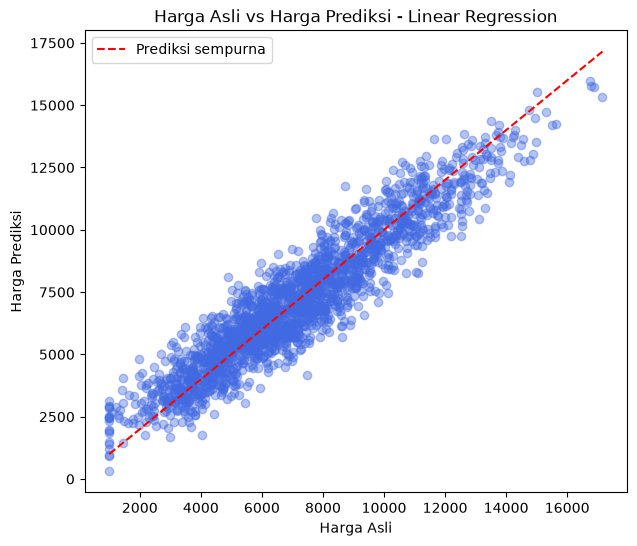

In [32]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Prediksi sempurna')
plt.xlabel('Harga Asli')
plt.ylabel('Harga Prediksi')
plt.title('Harga Asli vs Harga Prediksi - ' + best_name)
plt.legend()
plt.show()

**Penjelasan Grafik (Harga Asli vs Harga Prediksi):**
Setiap titik biru mewakili satu mobil pada data uji, dan **garis merah putus-putus** adalah patokan prediksi sempurna (harga prediksi = harga asli). Titik-titik biru tampak merapat mengikuti garis merah dari harga rendah sampai tinggi, menandakan akurasi model sudah baik dan merata.

### Analisis residual

Residual = harga asli - harga prediksi. Model yang bagus residualnya tersebar acak di sekitar 0, tidak membentuk pola, dan distribusinya mendekati normal.

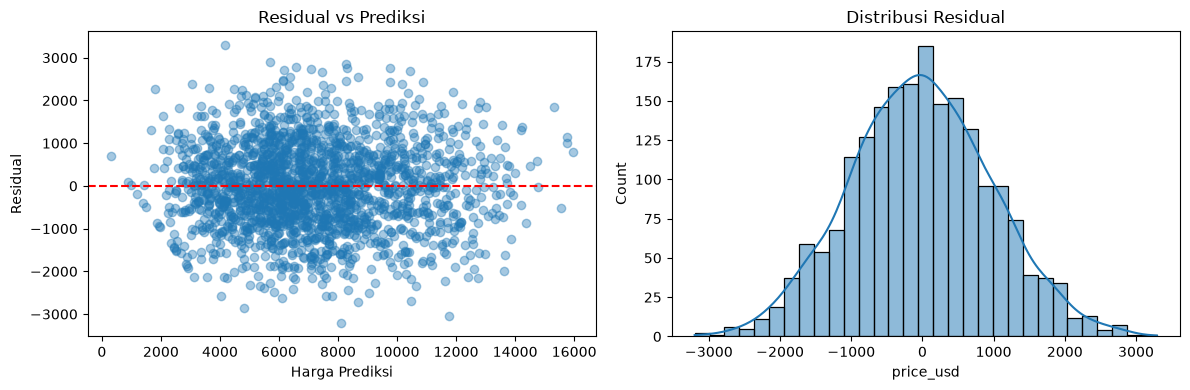

In [33]:
residual = y_test - y_pred

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(y_pred, residual, alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Harga Prediksi')
plt.ylabel('Residual')
plt.title('Residual vs Prediksi')

plt.subplot(1, 2, 2)
sns.histplot(residual, kde=True)
plt.title('Distribusi Residual')

plt.tight_layout()
plt.show()

**Penjelasan Grafik (Analisis Residual):**
- **Grafik Kiri (Residual vs Prediksi):** Selisih tebakan (`residual`) menyebar acak di atas dan bawah garis merah `0` tanpa membentuk pola melengkung, artinya model linear sudah tepat menangkap pola data. Garis miring tipis di sisi kiri muncul karena harga asli di dataset dipatok minimal $1.000, sedangkan rumus linear bisa memprediksi sedikit di bawah $1.000 untuk mobil paling tua bermesin kecil.
- **Grafik Kanan (Distribusi Residual):** Sebaran error berbentuk lonceng simetris tepat di sekitar angka `0`, menandakan prediksi model seimbang (tidak berat sebelah menebak terlalu mahal atau terlalu murah).

In [34]:
# error per kelompok umur mobil dan per merek (cari bagian yang prediksinya jelek)
cek = X_test.copy()
cek['error'] = np.abs(residual)
cek['kelompok_umur'] = pd.cut(cek['car_age'], bins=[0, 5, 10, 15, 20, 100])

print(cek.groupby('kelompok_umur', observed=True)['error'].mean().round(2))
print()
print(cek.groupby('brand')['error'].mean().round(2))

kelompok_umur
(0, 5]       855.99
(5, 10]      806.55
(10, 15]     772.10
(15, 20]     816.22
(20, 100]    762.56
Name: error, dtype: float64

brand
BMW           811.20
Chevrolet     773.82
Ford          743.39
Honda         760.49
Hyundai       800.36
Kia           825.68
Nissan        776.97
Tesla         752.21
Toyota        837.49
Volkswagen    845.41
Name: error, dtype: float64


**Penjelasan Kode:**
`pd.cut` membagi umur mobil ke dalam beberapa kelompok usia untuk memeriksa apakah model lemah pada segmen tertentu. Rata-rata error absolut di tiap kelompok umur maupun di tiap merek mobil relatif seragam (~$750–$840), sehingga model aman dipakai lintas merek dan usia mobil.

## 12. Fitur apa yang paling berpengaruh

Pakai permutation importance: satu fitur diacak, lalu dilihat seberapa besar error naik. Cara ini bisa dipakai untuk model apa saja.

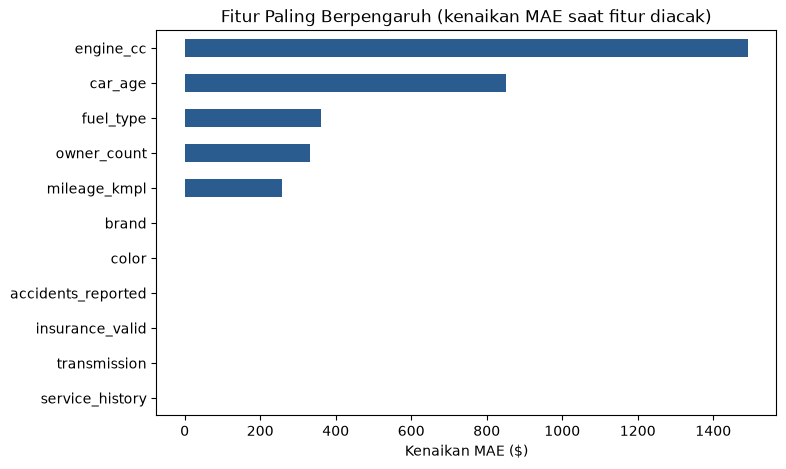

In [35]:
pi = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42,
                            scoring='neg_mean_absolute_error')

importance = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='#2b5c8f')
plt.gca().invert_yaxis()
plt.title('Fitur Paling Berpengaruh (kenaikan MAE saat fitur diacak)')
plt.xlabel('Kenaikan MAE ($)')
plt.show()

**Penjelasan Grafik (Permutation Importance):**
Semakin panjang batang ke kanan, semakin besar lonjakan error (MAE) ketika isi kolom tersebut diacak—artinya model sangat membutuhkan fitur tersebut.
- Lima fitur penentu utama secara berurutan adalah **`engine_cc`** (error naik ~$1.493 saat diacak), **`car_age`** (+$850), **`fuel_type`** (+$362), **`owner_count`** (+$333), dan **`mileage_kmpl`** (+$256).
- Enam fitur lainnya (`brand`, `color`, `accidents_reported`, `insurance_valid`, `transmission`, `service_history`) batangnya mendekati **0**, mengonfirmasi temuan EDA bahwa fitur-fitur tersebut hampir tidak memengaruhi harga pada dataset ini.

## 13. Contoh prediksi

In [36]:
sample_data = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_data)[0]

print(f"Harga Asli     : ${actual_price:,.2f}")
print(f"Harga Prediksi : ${predicted_price:,.2f}")
print(f"Selisih        : ${abs(actual_price - predicted_price):,.2f}")

Harga Asli     : $12,772.12
Harga Prediksi : $12,124.39
Selisih        : $647.73


**Penjelasan Kode:**
Mengambil sampel baris pertama dari `X_test` dengan kurung siku ganda `iloc[[0]]` agar tetap berbentuk `DataFrame` satu baris, lalu membandingkan harga aslinya dengan hasil prediksi model.

## 14. Kesimpulan

Berdasarkan seluruh tahapan eksperimen dari eksplorasi hingga evaluasi akhir, diperoleh kesimpulan berikut:
- **Model Terpilih:** **Linear Regression** terpilih karena menghasilkan nilai error *5-Fold Cross Validation* paling rendah (`RMSE CV ≈ $1.005,72`) dan bebas *overfitting*, mengingat pola hubungan fitur utama terhadap harga pada dataset ini memang bersifat linear/aditif.
- **Performa di Data Test:** Pada pengujian akhir menggunakan `X_test`, model mencatat **R² = 0,8765** (mampu menjelaskan 87,65% variasi harga), **MAE = $791,00**, dan **RMSE = $991,02**—jauh lebih akurat dibandingkan *Baseline Dummy* (`R² ≈ 0`, `MAE = $2.238`).
- **Dampak Hyperparameter Tuning:** Pembatasan kedalaman pohon (`max_depth`) dan ukuran daun (`min_samples_leaf`) lewat `GridSearchCV` terbukti berhasil menekan *overfitting* dan menurunkan error CV pada *Decision Tree*, *Random Forest*, serta *Gradient Boosting*.
- **Fitur Paling Berpengaruh:** Berdasarkan *Permutation Importance*, 5 penentu utama harga mobil bekas adalah **kapasitas mesin (`engine_cc`)**, **umur mobil (`car_age`)**, **jenis bahan bakar (`fuel_type`)**, **jumlah pemilik (`owner_count`)**, dan **efisiensi BBM (`mileage_kmpl`)**.

**Keterbatasan Proyek:**
- Prediksi hanya valid di dalam rentang data latih (tahun 1995–2023, mesin 800–5.000 cc, dan daftar merek yang tersedia).
- Dataset belum memuat fitur penting di pasar nyata seperti tipe/seri spesifik mobil, jarak tempuh odometer (km), lokasi penjualan, dan kondisi fisik bodi/mesin.
- Terdapat anomali bawaan dataset sintetis di mana mobil berbahan bakar `Electric` tetap tercatat memiliki kapasitas mesin (`engine_cc`).

## 15. Simpan model dan deploy

Yang disimpan: model (pipeline lengkap) dan daftar pilihan input untuk form aplikasi. Aplikasinya pakai Streamlit.

In [37]:
import os
os.makedirs('deploy', exist_ok=True)

# simpan model
joblib.dump(best_model, 'deploy/model_mobil.pkl')

# simpan info untuk form aplikasi
info = {
    'model': best_name,
    'mae_test': float(hasil.loc[best_name + ' (test)', 'MAE ($)']),
    'r2_test': float(hasil.loc[best_name + ' (test)', 'R2']),
    'pilihan': {col: sorted(df[col].unique().tolist()) for col in kolom_kat},
    'min_max': {col: [float(df[col].min()), float(df[col].max())] for col in kolom_angka},
    'urutan_kolom': X_train.columns.tolist()
}
with open('deploy/info.json', 'w') as f:
    json.dump(info, f, indent=2)

os.listdir('deploy')

['app.py', 'info.json', 'model_mobil.pkl', 'requirements.txt']

**Penjelasan Kode:**
`joblib.dump` membungkus seluruh `Pipeline` (`preprocessor` + model terbaik) ke file `model_mobil.pkl`, sedangkan `info.json` menyimpan daftar pilihan kategori, batas angka min-max, urutan kolom, dan metrik uji supaya form aplikasi Streamlit selalu sinkron dengan data pelatihan.

In [38]:
%%writefile deploy/app.py
import streamlit as st
import pandas as pd
import joblib
import json

model = joblib.load('model_mobil.pkl')
with open('info.json') as f:
    info = json.load(f)

pilihan = info['pilihan']
mm = info['min_max']

st.title('Prediksi Harga Mobil Bekas')
st.write('Model:', info['model'], '| R2 test:', round(info['r2_test'], 3), '| MAE test: $', round(info['mae_test']))

brand = st.selectbox('Merek', pilihan['brand'])
fuel_type = st.selectbox('Bahan bakar', pilihan['fuel_type'])
transmission = st.selectbox('Transmisi', pilihan['transmission'])
color = st.selectbox('Warna', pilihan['color'])
service_history = st.selectbox('Riwayat servis', pilihan['service_history'])
insurance_valid = st.selectbox('Asuransi masih berlaku', pilihan['insurance_valid'])

make_year = st.number_input('Tahun pembuatan', 1990, 2026, 2015)
engine_cc = st.number_input('Kapasitas mesin (cc)', int(mm['engine_cc'][0]), int(mm['engine_cc'][1]), 1500)
mileage_kmpl = st.number_input('Efisiensi bahan bakar (km/l)', float(mm['mileage_kmpl'][0]), float(mm['mileage_kmpl'][1]), 18.0)
owner_count = st.number_input('Jumlah pemilik sebelumnya', 1, 10, 2)
accidents_reported = st.number_input('Jumlah kecelakaan', 0, 10, 0)

if st.button('Prediksi'):
    data = pd.DataFrame([{
        'mileage_kmpl': mileage_kmpl,
        'engine_cc': engine_cc,
        'fuel_type': fuel_type,
        'owner_count': owner_count,
        'brand': brand,
        'transmission': transmission,
        'color': color,
        'service_history': service_history,
        'accidents_reported': accidents_reported,
        'insurance_valid': insurance_valid,
        'car_age': 2026 - make_year
    }])
    data = data[info['urutan_kolom']]
    harga = model.predict(data)[0]
    st.success(f'Perkiraan harga: ${harga:,.0f}')
    st.write(f"Kira-kira antara ${harga - info['mae_test']:,.0f} dan ${harga + info['mae_test']:,.0f}")

Overwriting deploy/app.py


In [39]:
# tes: model yang disimpan harus menghasilkan prediksi yang sama
model_load = joblib.load('deploy/model_mobil.pkl')

print(best_model.predict(X_test.head(3)))
print(model_load.predict(X_test.head(3)))

[12124.39047004  4688.22168024  7061.90011434]
[12124.39047004  4688.22168024  7061.90011434]


**Penjelasan Kode:**
Pengujian akhir sebelum *deploy*: memuat ulang file `model_mobil.pkl` dan memastikan hasil prediksinya untuk 3 data teratas sama persis dengan objek `best_model` di notebook.

Cara menjalankan aplikasi (di terminal):

```
pip install streamlit
cd deploy
streamlit run app.py
```

Untuk online, upload folder `deploy` ke GitHub lalu deploy lewat Streamlit Community Cloud. Tambahkan file `requirements.txt` yang isinya `scikit-learn`, `pandas`, `joblib`, `streamlit`.